# CNN propia · experiment03 · MixUp alpha=0.2

**Autores:** [completar] · **Experimento:** custom_experiment03

**Hipótesis:** MixUp puede mejorar validación y reducir errores de alta confianza.
**Referencia:** [custom experiment01](../experiment01/cnn_experiment01.ipynb), mejor custom anterior por accuracy.
**Único factor añadido: MixUp con alpha 0.2**, por imagen, solo en train y después de los giros y flips.
Cada imagen y su etiqueta se interpolan con una pareja del mismo lote usando la misma lambda.

Misma arquitectura `residual_se_v1`: etapas 32/64/128/256, bloques 2/2/2/2 con SE,
**2.857.125 parámetros**. Entrada **128×128**, batch **32**, AdamW, LR **0.001**,
weight decay **0.0001**, label smoothing **0.0**, máximo **200 épocas**, semilla **42**.
Sin Dropout adicional ni L2. Se conservan reparto histórico, aumentación geométrica y callbacks.

Se entrena desde cero. Validación, evaluación final de train y test mantienen imágenes originales;
la accuracy de entrenamiento durante `fit` usa etiquetas mezcladas y no mide lo mismo que antes.
El checkpoint y los callbacks usan `val_accuracy` sin mezcla.

Las rutas ya guardan el mejor `model.keras`, **siempre `prediction.json`**, artefactos y PDF aquí.
Se reutiliza la caché `mmap` de 128×128; no se guardan imágenes mezcladas en disco.
La comparación selecciona custom actual, custom experiment01 y ResNet18 experiment04,
con destino `comparisons/custom_experiment03/`. [Registro](../README.md).


## 1. Configuración

Dependencias: TensorFlow/Keras (con AdamW), NumPy, scikit-learn, Rasterio, Matplotlib y Jupyter.
No se instalan paquetes ni se descargan pesos.

Se conserva el orden original y el reparto histórico 90/10 con `random_state=1`, sin estratificación.
La semilla del entrenamiento es independiente. La caché pertenece a `cnn_challenge_alt/.cache/`.


In [1]:
from pathlib import Path
import csv
import hashlib
import json
import platform
import tempfile
import time
import warnings

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support,
                             precision_recall_curve, average_precision_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def read_json(path):
    with Path(path).open(encoding='utf-8') as stream:
        return json.load(stream)

def write_json(path, data):
    with Path(path).open('w', encoding='utf-8') as stream:
        json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)

def digest_json(data):
    return hashlib.sha256(json.dumps(data, sort_keys=True).encode()).hexdigest()


def artifact_path(run_dir, filename):
    """Leer artifacts/; aceptar también los resultados antiguos en la raíz."""
    path = Path(run_dir) / 'artifacts' / filename
    return path if path.exists() else Path(run_dir) / filename


def save_figure(fig, directory, name):
    directory.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(directory / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

# EDITAR: identidad, hipótesis y factores que se modifican.
CFG = {
    'experiment_id': 'custom_experiment03',
    'hypothesis': 'Evaluar MixUp alpha=0.2 sobre experiment01, a 128x128 y sin label smoothing, para mejorar validación y reducir errores de alta confianza.',
    'architecture': 'custom',       # custom | resnet18 | densenet121 | efficientnet_b0 | mobilenet_v2
    'seed': 42,
    'deterministic': True,
    'image_size': [128, 128],         # [alto, ancho]; 32, 64, 96, 128, 224...
    'batch_size': 32,
    'max_epochs': 200,
    'optimizer': 'adamw',            # sgd | adam | adamw
    'learning_rate': 1e-3,
    'momentum': 0.9,
    'clipnorm': None,
    'custom_variant': 'residual_se_v1',
    'filters': [32, 64, 128, 256],  # canales de las cuatro etapas
    'blocks_per_stage': [2, 2, 2, 2],
    'se_ratio': 8,                 # reducción de canales en atención SE
    'convs_per_block': 2,
    'kernel_size': 3,
    'batch_norm': True,           # solo CNN propia; las populares conservan sus BN originales
    'dropout': 0.0,                # tras GAP, antes del clasificador
    'l2': 0.0,                    # CNN propia; las populares requieren 0 en esta plantilla
    'augmentation': True,
    'weight_decay': 0.0001,           # desacoplado, solo AdamW; no equivale a L2
    'label_smoothing': 0.0,
    'mixup_alpha': 0.2,            # 0 desactiva; >0 usa Beta(alpha, alpha) por imagen
    'lr_factor': 0.5,
    'lr_patience': 10,
    'stop_patience': 20,
    'min_lr': 1e-06,
    'monitor': 'val_accuracy',
    'monitor_mode': 'max',
}
# EDITAR al copiar: ruta del notebook relativa a PROJECT (también admite una ruta absoluta).
# Los archivos model.keras y prediction.json se escriben en la carpeta de esta ruta.
NOTEBOOK_PATH = Path('cnn_challenge_alt/experiments/experiment03/cnn_experiment03.ipynb')
CACHE_MODE = 'mmap'                # Siempre lotes desde la caché en disco
DATA_DIR_OVERRIDE = None            # p. ej. Path('/ruta/xview_recognition')
PROJECT_DIR_OVERRIDE = None         # si se lanza Jupyter fuera del repositorio

CATEGORY_NAMES = ['Cargo plane', 'Small car', 'Bus', 'Truck', 'Motorboat',
                  'Fishing vessel', 'Dump truck', 'Excavator', 'Building',
                  'Helipad', 'Storage tank', 'Shipping container', 'Pylon']
CLASS_TO_INDEX = {name: i for i, name in enumerate(CATEGORY_NAMES)}
NUM_CLASSES = len(CATEGORY_NAMES)
SPLIT_SPEC = {'validation_fraction': 0.1, 'random_state': 1, 'shuffle': True, 'stratify': None}

def find_project_dir():
    if PROJECT_DIR_OVERRIDE is not None:
        project = Path(PROJECT_DIR_OVERRIDE).expanduser().resolve()
        if not (project / 'cnn_challenge_alt').is_dir():
            raise FileNotFoundError(f'PROJECT_DIR_OVERRIDE debe apuntar a PROJECT: {project}')
        return project
    # Funciona desde la raíz del clon, PROJECT o cualquier carpeta de experimentos.
    # Una ruta absoluta del notebook permite localizar PROJECT incluso desde fuera del clon.
    notebook = Path(NOTEBOOK_PATH).expanduser()
    starts = [Path.cwd()]
    if notebook.is_absolute():
        starts.append(notebook.parent)
    for start in starts:
        for parent in (start, *start.parents):
            for candidate in (parent, parent / 'PROJECT'):
                if (candidate / 'cnn_challenge_alt').is_dir():
                    return candidate.resolve()
    raise FileNotFoundError('Define PROJECT_DIR_OVERRIDE con la ruta local a PROJECT.')


def project_path(path):
    """Las rutas relativas de configuración siempre se interpretan desde PROJECT."""
    path = Path(path).expanduser()
    return (path if path.is_absolute() else PROJECT_DIR / path).resolve()


PROJECT_DIR = find_project_dir()
DATA_DIR = project_path(DATA_DIR_OVERRIDE if DATA_DIR_OVERRIDE is not None else 'xview_recognition')
CHALLENGE_DIR = PROJECT_DIR / 'cnn_challenge_alt'
CACHE_DIR = CHALLENGE_DIR / '.cache'
NOTEBOOK_PATH = project_path(NOTEBOOK_PATH)
if not NOTEBOOK_PATH.is_file() or NOTEBOOK_PATH.suffix != '.ipynb':
    raise FileNotFoundError(f'Ajusta NOTEBOOK_PATH al notebook que estás ejecutando: {NOTEBOOK_PATH}')
RUN_DIR = NOTEBOOK_PATH.parent
ARTIFACTS_DIR = RUN_DIR / 'artifacts'

assert CFG['mixup_alpha'] >= 0
assert CACHE_MODE == 'mmap'
if CFG['monitor'] not in ('val_accuracy', 'val_loss', 'val_ce'):
    raise ValueError('Monitor permitido: val_accuracy, val_loss o val_ce.')
assert CFG['monitor_mode'] == ('max' if CFG['monitor'] == 'val_accuracy' else 'min')
assert CFG['stop_patience'] > CFG['lr_patience']
assert len(CFG['image_size']) == 2 and min(CFG['image_size']) >= 8
assert CFG['batch_size'] > 0 and CFG['max_epochs'] > 0
assert 0 <= CFG['dropout'] < 1 and CFG['l2'] >= 0
assert 0 <= CFG['label_smoothing'] < 1 and CFG['weight_decay'] >= 0
assert 0 < CFG['lr_factor'] < 1 and 0 < CFG['min_lr'] <= CFG['learning_rate']
assert CFG['optimizer'] in ('sgd', 'adam', 'adamw')
if CFG['optimizer'] != 'adamw' and CFG['weight_decay'] != 0:
    raise ValueError('weight_decay requiere AdamW; usa l2 para penalización en la CNN propia.')
if CFG['augmentation'] and CFG['image_size'][0] != CFG['image_size'][1]:
    raise ValueError('Las rotaciones de 90° requieren imágenes cuadradas.')
assert Path(CFG['experiment_id']).name == CFG['experiment_id'] and CFG['experiment_id'] not in ('', '.', '..')
keras.utils.set_random_seed(CFG['seed'])
if CFG['deterministic']:
    tf.config.experimental.enable_op_determinism()
GPUS = tf.config.list_physical_devices('GPU')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # El dispositivo ya estaba inicializado en este kernel.
print('TensorFlow:', tf.__version__, '| GPU:', GPUS)
print('Datos:', DATA_DIR, '\nResultados:', RUN_DIR)


2026-11-08 03:14:00.184636: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-08 03:14:00.221546: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-08 03:14:00.221566: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-08 03:14:00.224280: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-08 03:14:00.232342: I tensorflow/core/platform/cpu_feature_guar

TensorFlow: 2.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Datos: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/xview_recognition 
Resultados: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge_alt/experiments/experiment03


2026-11-08 03:14:01.871838: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 03:14:02.009016: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 03:14:02.009066: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## 2. Anotaciones y reparto verificable

Unimos anotaciones por `image_id`, evitando depender de que dos diccionarios tengan el mismo orden.
El orden de las imágenes se conserva para reproducir exactamente el reparto anterior. Guardamos nombres,
etiquetas y un hash del reparto para detectar comparaciones incompatibles. Mostramos el soporte de las clases:
Helipad tiene muy pocas muestras y su recall puede variar mucho.

In [2]:
ANNOTATION_PATH = DATA_DIR / 'xview_ann_train.json'
raw = read_json(ANNOTATION_PATH)
annotations_by_id = {}
for ann in raw['annotations'].values():
    key = ann['image_id']
    if key in annotations_by_id:
        raise ValueError(f'Se esperaba un solo objeto por recorte: {key}')
    annotations_by_id[key] = ann
records = []
for image in raw['images'].values():
    ann = annotations_by_id[image['image_id']]
    label = CLASS_TO_INDEX[ann['category_id']]
    records.append({'filename': image['filename'], 'label': label, 'image_id': image['image_id']})
if len({r['filename'] for r in records}) != len(records):
    raise ValueError('Hay imágenes repetidas.')
indices = np.arange(len(records))
train_idx, valid_idx = train_test_split(
    indices, test_size=SPLIT_SPEC['validation_fraction'], random_state=SPLIT_SPEC['random_state'],
    shuffle=True, stratify=None,
)
labels = np.array([r['label'] for r in records], dtype=np.int32)
SPLIT_MANIFEST = {
    'spec': SPLIT_SPEC,
    'train': [records[i] for i in train_idx],
    'valid': [records[i] for i in valid_idx],
}
SPLIT_HASH = digest_json(SPLIT_MANIFEST)
DATA_HASH = hashlib.sha256(ANNOTATION_PATH.read_bytes()).hexdigest()
assert not set(train_idx) & set(valid_idx)
print(f'Train: {len(train_idx)} | Validación: {len(valid_idx)} | hash: {SPLIT_HASH[:12]}')
print(f"{'Clase':22} {'train':>7} {'valid':>7}")
for i, name in enumerate(CATEGORY_NAMES):
    print(f'{name:22} {np.sum(labels[train_idx] == i):7} {np.sum(labels[valid_idx] == i):7}')
if set(labels[valid_idx]) != set(range(NUM_CLASSES)):
    raise ValueError('Hay clases ausentes en validación: revisar el protocolo antes de continuar.')

Train: 16871 | Validación: 1875 | hash: f7d0f1df9d98
Clase                    train   valid
Cargo plane                576      59
Small car                 2995     329
Bus                       1594     174
Truck                     1969     241
Motorboat                  960     109
Fishing vessel             633      73
Dump truck                1118     118
Excavator                  708      81
Building                  3231     363
Helipad                    102       9
Storage tank              1317     152
Shipping container        1388     135
Pylon                      280      32


## 3. Caché en disco y lotes

Los experimentos de esta versión comparten su propia caché `PROJECT/cnn_challenge_alt/.cache/`: RGB float32 [0,1],
reducción con `Resampling.average`, escritura imagen a imagen y publicación atómica.
La clave incluye raíz, anotaciones, orden de archivos, resolución y preprocesamiento.
**Si cambias el contenido de los TIFF, elimina su caché**. A 128×128 ocupa unos 3,43 GiB.

Siempre se abre con `mmap`: solo se copian lotes y se anticipa un lote. Las etiquetas son one-hot
para usar Categorical Cross Entropy y permitir label smoothing.
Si `augmentation=True`, cada imagen de train recibe una rotación uniforme entre 0°, 90°, 180°, 270°
y flips horizontal/vertical independientes con p=0.5. Se aplica en el dataset de entrenamiento;
validación, evaluación de train y test conservan sus píxeles sin aumentación.

**MixUp solo en train:** después de los giros y flips, cada imagen se mezcla con otra de su lote
mediante lambda ~ Beta(0.2, 0.2), independiente por imagen. La misma lambda y pareja se aplican
a sus etiquetas one-hot. Una permutación puede dejar alguna imagen emparejada consigo misma;
un lote final de una sola imagen permanece idéntico. Los sorteos usan un RNG NumPy propio,
semilla `seed+1000`, que avanza entre épocas sin alterar el RNG de barajado.
Validación y evaluación de train se construyen con MixUp desactivado. La caché conserva los píxeles originales.


In [3]:
def read_image(path, image_size):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
        with rasterio.open(path) as src:
            if src.count != 3 or any(dtype != 'uint8' for dtype in src.dtypes):
                raise ValueError(f'Se esperaba RGB uint8: {path}')
            bands = src.read(out_shape=(3, *image_size), out_dtype='float32', resampling=Resampling.average)
    return np.moveaxis(bands, 0, -1) / np.float32(255.0)

def prepare_cache(records, image_size):
    # Incluye raíz del dataset: no mezclar copias distintas con las mismas anotaciones.
    spec = {'data_dir': str(DATA_DIR.resolve()), 'data_hash': DATA_HASH,
            'files': [r['filename'] for r in records], 'image_size': list(image_size),
            'reader': 'rasterio-average-float32-rgb-div255-v1'}
    key = digest_json(spec)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    path = CACHE_DIR / f'{key}.npy'
    shape = (len(records), *image_size, 3)
    print(f'Caché de imágenes: {np.prod(shape) * 4 / 1024**3:.2f} GiB en disco; modo mmap')
    if not path.exists():
        # Escribir imagen a imagen: tampoco durante la creación se reserva el array completo en RAM.
        with tempfile.NamedTemporaryFile(dir=CACHE_DIR, suffix='.tmp.npy', delete=False) as stream:
            temp = Path(stream.name)
        try:
            array = np.lib.format.open_memmap(temp, mode='w+', dtype=np.float32, shape=shape)
            try:
                for i, record in enumerate(records):
                    array[i] = read_image(DATA_DIR / record['filename'], image_size)
                    if (i + 1) % 2000 == 0:
                        print(f'  {i + 1}/{len(records)}')
                array.flush()
            finally:
                del array
            temp.replace(path)  # Solo publicar una caché completamente escrita.
        finally:
            temp.unlink(missing_ok=True)
    array = np.load(path, mmap_mode='r', allow_pickle=False)
    if array.shape != shape or array.dtype != np.float32:
        raise ValueError(f'Caché incompatible: elimina {path} y vuelve a preparar los datos.')
    return array

load_start = time.perf_counter()
x_all = prepare_cache(records, CFG['image_size'])
load_seconds = time.perf_counter() - load_start
print(f'Datos preparados en {load_seconds:.1f} s; forma: {x_all.shape}')

def make_dataset(array, all_labels, selected_idx, batch_size, shuffle=False, seed=42, augment=False, mixup_alpha=0.0):
    # Un generador por dataset, con RNG independiente de la inicialización del modelo.
    if mixup_alpha < 0:
        raise ValueError("mixup_alpha debe ser no negativo.")
    rng = np.random.default_rng(seed)
    mix_rng = np.random.default_rng(seed + 1000)  # Independiente del orden de los ejemplos.
    selected_idx = np.asarray(selected_idx)
    def batches():
        order = rng.permutation(selected_idx) if shuffle else selected_idx
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            images = np.asarray(array[batch], dtype=np.float32)
            targets = np.eye(NUM_CLASSES, dtype=np.float32)[all_labels[batch]]
            if mixup_alpha > 0:
                weights = mix_rng.beta(mixup_alpha, mixup_alpha, size=len(batch)).astype(np.float32)
                partners = mix_rng.permutation(len(batch)).astype(np.int32)
                yield images, targets, weights, partners
            else:
                yield images, targets
    signature = (tf.TensorSpec((None, *array.shape[1:]), tf.float32),
                 tf.TensorSpec((None, NUM_CLASSES), tf.float32))
    if mixup_alpha > 0:
        signature += (tf.TensorSpec((None,), tf.float32), tf.TensorSpec((None,), tf.int32))
    ds = tf.data.Dataset.from_generator(batches, output_signature=signature)
    ds = ds.apply(tf.data.experimental.assert_cardinality(int(np.ceil(len(selected_idx) / batch_size))))
    options = tf.data.Options()
    options.experimental_deterministic = True
    ds = ds.with_options(options)
    if augment:
        def augment_batch(images, targets, *mix_metadata):
            def augment_image(image):
                k = tf.random.uniform((), maxval=4, dtype=tf.int32)
                image = tf.image.rot90(image, k)
                image = tf.image.random_flip_left_right(image)
                return tf.image.random_flip_up_down(image)
            images = tf.map_fn(augment_image, images,
                               fn_output_signature=tf.TensorSpec(array.shape[1:], tf.float32))
            return (images, targets, *mix_metadata)
        ds = ds.map(augment_batch, num_parallel_calls=1, deterministic=True)
    if mixup_alpha > 0:
        # Mezclar después de transformar cada imagen; usar idéntico lambda y pareja para imagen/etiqueta.
        def mixup_batch(images, targets, weights, partners):
            image_weights = tf.reshape(weights, (-1, 1, 1, 1))
            label_weights = tf.reshape(weights, (-1, 1))
            paired_images = tf.gather(images, partners)
            paired_targets = tf.gather(targets, partners)
            return (image_weights * images + (1.0 - image_weights) * paired_images,
                    label_weights * targets + (1.0 - label_weights) * paired_targets)
        ds = ds.map(mixup_batch, num_parallel_calls=1, deterministic=True)
    return ds.prefetch(1)

train_ds = make_dataset(x_all, labels, train_idx, CFG['batch_size'], True, CFG['seed'], augment=CFG['augmentation'],
                        mixup_alpha=CFG['mixup_alpha'])
valid_ds = make_dataset(x_all, labels, valid_idx, CFG['batch_size'])
train_eval_ds = make_dataset(x_all, labels, train_idx, CFG['batch_size'])


Caché de imágenes: 3.43 GiB en disco; modo mmap
Datos preparados en 0.0 s; forma: (18746, 128, 128, 3)


2026-11-08 03:14:02.138101: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 03:14:02.138181: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 03:14:02.138216: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 03:14:02.296143: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-08 03:14:02.296199: I external/local_xla/xla/stream_executor

## 4. Arquitectura propia

| Etapa | Operaciones | Salida para entrada 128×128 |
|---|---|---|
| Entrada | RGB [0,1] | 128×128×3 |
| Stem | Conv3×3-32 + BN + ReLU; Conv3×3-32/stride2 + BN + ReLU | 64×64×32 |
| Etapa 1 | 2 bloques residuales con SE, 32 canales | 64×64×32 |
| Etapa 2 | 2 bloques residuales con SE, 64 canales; primero stride2 | 32×32×64 |
| Etapa 3 | 2 bloques residuales con SE, 128 canales; primero stride2 | 16×16×128 |
| Etapa 4 | 2 bloques residuales con SE, 256 canales; primero stride2 | 8×8×256 |
| Cabeza | Global Average Pooling + Dense13 softmax | 13 probabilidades |

Tamaño verificado: **2.857.125 parámetros totales** (2.852.261 entrenables).

Cada bloque usa Conv3×3 → BN → ReLU → Conv3×3 → BN → SE → suma residual → ReLU.
Al reducir tamaño o cambiar canales, el atajo usa Conv1×1 + BN. SE obtiene un resumen espacial
por canal y aprende pesos con Dense(C/8, ReLU) → Dense(C, sigmoid), aplicados al mapa de características.

Se conserva más resolución al inicio que en el stem de ResNet18 de referencia (sin Conv7×7 ni MaxPool).
La hipótesis es preservar detalles de objetos pequeños; se evaluará con los resultados, sin asumir ventaja.
BatchNorm y la atención forman parte de la arquitectura y quedan registradas en CFG y architecture.json.
No se añaden Dropout, label smoothing ni penalización L2.

Inspiración: [conexiones residuales](https://openaccess.thecvf.com/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html)
y [Squeeze-and-Excitation](https://openaccess.thecvf.com/content_cvpr_2018/html/Hu_Squeeze-and-Excitation_Networks_CVPR_2018_paper.html).
`build_custom_body` implementa esta red; el catálogo popular del baseline se conserva para futuras copias.


In [4]:
def conv_bn_relu(x, filters, kernel_size, strides=1):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding='same',
                      use_bias=False, kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def custom_conv(x, channels, kernel, stride, cfg, name, activation=True):
    reg = keras.regularizers.l2(cfg['l2']) if cfg['l2'] else None
    x = layers.Conv2D(channels, kernel, strides=stride, padding='same',
                      use_bias=not cfg['batch_norm'], kernel_initializer='he_normal',
                      kernel_regularizer=reg, name=name + '_conv')(x)
    if cfg['batch_norm']:
        x = layers.BatchNormalization(name=name + '_bn')(x)
    if activation:
        x = layers.Activation('relu', name=name + '_relu')(x)
    return x


def custom_se(x, channels, ratio, name):
    # Atención de canales con capas estándar: el .keras no necesita custom_objects.
    gate = layers.GlobalAveragePooling2D(name=name + '_squeeze')(x)
    gate = layers.Dense(max(channels // ratio, 1), activation='relu',
                        name=name + '_reduce')(gate)
    gate = layers.Dense(channels, activation='sigmoid', name=name + '_expand')(gate)
    gate = layers.Reshape((1, 1, channels), name=name + '_reshape')(gate)
    return layers.Multiply(name=name + '_scale')([x, gate])


def custom_residual_block(x, channels, stride, cfg, name):
    shortcut = x
    y = x
    for i in range(cfg['convs_per_block']):
        y = custom_conv(y, channels, cfg['kernel_size'], stride if i == 0 else 1,
                        cfg, f'{name}_main{i + 1}',
                        activation=(i < cfg['convs_per_block'] - 1))
    y = custom_se(y, channels, cfg['se_ratio'], name + '_se')
    if stride != 1 or int(shortcut.shape[-1]) != channels:
        shortcut = custom_conv(shortcut, channels, 1, stride, cfg,
                               name + '_shortcut', activation=False)
    x = layers.Add(name=name + '_add')([shortcut, y])
    return layers.Activation('relu', name=name + '_out')(x)


def build_custom_body(inputs, cfg):
    if cfg['custom_variant'] != 'residual_se_v1':
        raise ValueError('Variante propia desconocida.')
    widths, blocks = cfg['filters'], cfg['blocks_per_stage']
    if not widths or len(widths) != len(blocks) or min(widths + blocks) < 1:
        raise ValueError('Canales y bloques deben ser listas positivas de igual longitud.')
    if cfg['convs_per_block'] < 2 or cfg['se_ratio'] < 1:
        raise ValueError('Se requieren al menos dos convoluciones por bloque y se_ratio positivo.')
    if min(cfg['image_size']) < 2 ** len(widths):
        raise ValueError('Resolución insuficiente para las reducciones espaciales.')
    # Dos convoluciones pequeñas; solo la segunda reduce, sin MaxPool inicial.
    x = custom_conv(inputs, widths[0], 3, 1, cfg, 'stem1')
    x = custom_conv(x, widths[0], 3, 2, cfg, 'stem2')
    for stage, (channels, count) in enumerate(zip(widths, blocks), 1):
        for block in range(1, count + 1):
            stride = 2 if stage > 1 and block == 1 else 1
            x = custom_residual_block(x, channels, stride, cfg, f's{stage}_b{block}')
    return x

def residual_basic_block(x, filters, stride):
    skip = x
    y = conv_bn_relu(x, filters, 3, stride)
    y = layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_initializer='he_normal')(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or int(skip.shape[-1]) != filters:
        skip = layers.Conv2D(filters, 1, strides=stride, use_bias=False)(skip)
        skip = layers.BatchNormalization()(skip)
    return layers.Activation('relu')(layers.Add()([skip, y]))

ARCHITECTURES = ('custom', 'resnet18', 'densenet121', 'efficientnet_b0', 'mobilenet_v2')
APPLICATIONS = {
    'densenet121': keras.applications.DenseNet121,
    'efficientnet_b0': keras.applications.EfficientNetB0,
    'mobilenet_v2': keras.applications.MobileNetV2,
}

def build_model(cfg):
    name = cfg['architecture']
    if name not in ARCHITECTURES:
        raise ValueError(f'Arquitectura desconocida: {name}; opciones: {ARCHITECTURES}')
    if name != 'custom' and (min(cfg['image_size']) < 32 or cfg['l2'] != 0):
        raise ValueError('Las populares requieren al menos 32×32 y l2=0; admiten AdamW.')
    inputs = keras.Input(shape=(*cfg['image_size'], 3), name='rgb_0_1')
    if name == 'custom':
        x = build_custom_body(inputs, cfg)
    elif name == 'resnet18':
        x = conv_bn_relu(inputs, 64, 7, 2)
        x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
        for stage, filters in enumerate((64, 128, 256, 512)):
            for block in range(2):
                x = residual_basic_block(x, filters, 2 if stage > 0 and block == 0 else 1)
    else:
        x = layers.Rescaling(255.0)(inputs) if name == 'efficientnet_b0' else inputs
        backbone = APPLICATIONS[name](weights=None, include_top=False,
                                      input_shape=(*cfg['image_size'], 3))
        backbone.trainable = True
        x = backbone(x)
    x = layers.GlobalAveragePooling2D()(x)
    if cfg['dropout']:
        x = layers.Dropout(cfg['dropout'], seed=cfg['seed'] + 2)(x)
    reg = keras.regularizers.l2(cfg['l2']) if cfg['l2'] else None
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', kernel_regularizer=reg,
                           name='classification')(x)
    return keras.Model(inputs, outputs, name=f'{name}_scratch')


def compile_model(model, cfg):
    common = {'learning_rate': cfg['learning_rate'], 'clipnorm': cfg['clipnorm']}
    if cfg['optimizer'] == 'sgd':
        optimizer = keras.optimizers.SGD(momentum=cfg['momentum'], nesterov=True, **common)
    elif cfg['optimizer'] == 'adam':
        optimizer = keras.optimizers.Adam(**common)
    elif cfg['optimizer'] == 'adamw':
        optimizer = keras.optimizers.AdamW(weight_decay=cfg['weight_decay'], **common)
    else:
        raise ValueError('Optimizador desconocido.')
    model.compile(optimizer=optimizer,
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=cfg['label_smoothing']),
                  metrics=[keras.metrics.CategoricalAccuracy(name='accuracy'),
                           keras.metrics.CategoricalCrossentropy(name='ce')])
    return model

print('Arquitecturas:', ', '.join(ARCHITECTURES))
keras.backend.clear_session()
keras.utils.set_random_seed(CFG['seed'])
model = compile_model(build_model(CFG), CFG)
model.summary()
assert all(layer.trainable for layer in model.layers)
INITIAL_HASH = hashlib.sha256(b''.join(w.tobytes() for w in model.get_weights())).hexdigest()


Arquitecturas: custom, resnet18, densenet121, efficientnet_b0, mobilenet_v2
Model: "custom_scratch"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 rgb_0_1 (InputLayer)        [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 stem1_conv (Conv2D)         (None, 128, 128, 32)         864       ['rgb_0_1[0][0]']             
                                                                                                  
 stem1_bn (BatchNormalizati  (None, 128, 128, 32)         128       ['stem1_conv[0][0]']          
 on)                                                                                              
                                                                                                  
 stem1_re

## 5. Entrenamiento y artefactos

Se selecciona el **primer máximo de `val_accuracy`** por defecto. Todos los callbacks de selección usan el mismo
monitor, modo y `min_delta=0`. EarlyStopping restaura los mejores pesos; la evaluación y el test recargan el checkpoint.
Se conserva el historial en disco cada época; la evaluación recarga siempre el mejor checkpoint.
El modelo y las predicciones se guardan en `RUN_DIR`; configuración, historial, métricas y demás
auxiliares se guardan en `RUN_DIR/artifacts/`. Al repetir en esa carpeta se sobrescriben;
para conservar otro experimento, copia el notebook en otra carpeta y actualiza `NOTEBOOK_PATH`.

`loss` incluye label smoothing y L2 cuando se configuran; `ce` mide CE sin suavizado ni L2. Las curvas de entrenamiento incluyen Dropout,
aumentación y BN en modo entrenamiento; la brecha final se calcula aparte, en inferencia sobre ambos conjuntos.
Los tiempos dependen del hardware, tamaño y batch: se guardan para contextualizar la comparación, no como benchmark universal.

**Lectura del historial con MixUp:** `accuracy`, `loss` y `ce` de train se calculan sobre imágenes
y etiquetas mezcladas; la accuracy usa el argmax de la etiqueta blanda y no es comparable directamente
con train de experiment01. Las métricas `val_*` siguen usando datos originales. El checkpoint,
el ajuste del LR y la parada dependen exclusivamente de `val_accuracy` sin mezcla.
La brecha final se obtiene evaluando train y validación sin MixUp en la sección 7.


In [5]:
class EpochTelemetry(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
        self.lr = float(keras.backend.get_value(self.model.optimizer.learning_rate))
    def on_epoch_end(self, epoch, logs=None):
        logs['epoch_seconds'] = time.perf_counter() - self.start
        logs['lr_used'] = self.lr

def make_callbacks(run_dir, cfg):
    return [
        EpochTelemetry(),
        keras.callbacks.ModelCheckpoint(str(run_dir / 'model.keras'), monitor=cfg['monitor'],
                                        mode=cfg['monitor_mode'], save_best_only=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor=cfg['monitor'], mode=cfg['monitor_mode'], min_delta=0,
                                         factor=cfg['lr_factor'], patience=cfg['lr_patience'],
                                         min_lr=cfg['min_lr'], verbose=1),
        keras.callbacks.EarlyStopping(monitor=cfg['monitor'], mode=cfg['monitor_mode'], min_delta=0,
                                      patience=cfg['stop_patience'], restore_best_weights=True, verbose=1),
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.CSVLogger(str(run_dir / 'artifacts' / 'history.csv')),
    ]

def start_run(model, cfg, run_dir):
    # La carpeta es la del propio notebook. Reejecutar actualiza sus resultados.
    run_dir.mkdir(parents=True, exist_ok=True)
    artifacts_dir = run_dir / 'artifacts'
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    # Evitar que una ejecución interrumpida conserve métricas/predicciones del modelo anterior.
    for name in ('model.keras', 'prediction.json'):
        (run_dir / name).unlink(missing_ok=True)
    for name in ('metrics.json', 'history.json', 'timing.json',
                 'validation_predictions.npz', 'class_metrics.csv'):
        (artifacts_dir / name).unlink(missing_ok=True)
        (run_dir / name).unlink(missing_ok=True)  # Compatibilidad al repetir una ejecución antigua.
    config = {
        **cfg, 'weights': None, 'all_layers_trainable': True,
        'head': 'GAP-' + ('Dropout-' if cfg['dropout'] else '') + 'Dense13',
        'class_names': CATEGORY_NAMES, 'split_hash': SPLIT_HASH, 'data_hash': DATA_HASH,
        'split_spec': SPLIT_SPEC, 'preprocessing': 'rasterio-average-float32-rgb-div255-v1',
        'data_load_seconds': load_seconds, 'cache_mode': CACHE_MODE,
        'loss': 'categorical_crossentropy',
        'augmentation_spec': {'quarter_turns': [0, 90, 180, 270],
                              'horizontal_flip_probability': 0.5, 'vertical_flip_probability': 0.5}
                             if cfg['augmentation'] else None,
        'mixup_spec': {'alpha': cfg['mixup_alpha'], 'distribution': 'Beta(alpha, alpha)',
                       'lambda_per_image': True, 'pairing': 'within_batch_permutation',
                       'order': 'after_geometric_augmentation', 'rng_seed_offset': 1000,
                       'train_only': True},
        'train_history_targets': 'mixup_soft_targets',
        'restore_best_weights': True, 'checkpoint_save_best_only': True,
        'initial_weights_sha256': INITIAL_HASH,
        'environment': {'python': platform.python_version(), 'tensorflow': tf.__version__,
                        'numpy': np.__version__, 'rasterio': rasterio.__version__,
                        'platform': platform.platform(),
                        'gpu': [tf.config.experimental.get_device_details(g).get('device_name', str(g)) for g in GPUS]},
    }
    write_json(artifacts_dir / 'config.json', config)
    write_json(artifacts_dir / 'split.json', SPLIT_MANIFEST)
    (artifacts_dir / 'architecture.json').write_text(model.to_json(), encoding='utf-8')
    with (artifacts_dir / 'model_summary.txt').open('w') as stream:
        model.summary(print_fn=lambda line, **kwargs: stream.write(line + '\n'))
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=valid_ds, epochs=cfg['max_epochs'],
                        callbacks=make_callbacks(run_dir, cfg), verbose=1)
    seconds = time.perf_counter() - start
    values = {k: [float(x) for x in v] for k, v in history.history.items()}
    write_json(artifacts_dir / 'history.json', values)
    write_json(artifacts_dir / 'timing.json', {'fit_seconds': seconds})
    return values, seconds

history, fit_seconds = start_run(model, CFG, RUN_DIR)


2026-11-08 03:14:03.067858: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


Epoch 1/200


2026-11-08 03:14:06.676597: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-11-08 03:14:07.230763: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-11-08 03:14:07.539667: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-11-08 03:14:08.344666: I external/local_xla/xla/service/service.cc:168] XLA service 0x798388536230 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-08 03:14:08.344699: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Ti, Compute Capability 8.9
2026-11-08 03:14:08.360104: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794104048.471992  103432 device_compil

528/528 [==============================] - ETA: 0s - loss: 1.8711 - accuracy: 0.3806 - ce: 1.8711
Epoch 1: val_accuracy improved from -inf to 0.47413, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge_alt/experiments/experiment03/model.keras
528/528 [==============================] - 33s 43ms/step - loss: 1.8711 - accuracy: 0.3806 - ce: 1.8711 - val_loss: 1.6048 - val_accuracy: 0.4741 - val_ce: 1.6048 - epoch_seconds: 32.3518 - lr_used: 0.0010 - lr: 0.0010
Epoch 2/200
528/528 [==============================] - ETA: 0s - loss: 1.5735 - accuracy: 0.4940 - ce: 1.5735
Epoch 2: val_accuracy improved from 0.47413 to 0.53333, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge_alt/experiments/experiment03/model.keras
528/528 [==============================] - 23s 43ms/step - loss: 1.5735 - accuracy: 0.4940 - ce: 1.5735 - val_loss: 1.4033 - val_accuracy: 0.5333 - val_ce: 1.4033 - epoch_seconds: 22.5715 - lr_use

## 6. Predicción del test · se genera siempre al ejecutar el notebook completo

Se recarga el mejor `model.keras` y se guarda **`prediction.json` junto a este notebook**, con el mismo
esquema que antes: `images` y `annotations`, categorías como texto, bbox y dimensiones originales
(224×224 en este dataset), aunque la entrada de la red se reduzca. No se crea ningún ZIP.
Así se pueden compartir las predicciones con compañeros sin que tengan que volver a entrenar.

El test no tiene etiquetas públicas; sus nombres de carpeta no se usan como clases y no se utiliza
para ajustar hiperparámetros. Se lee cada imagen una vez y se predice por lotes.


In [6]:
def generate_predictions(run_dir, data_dir):
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    trained = keras.models.load_model(str(run_dir / 'model.keras'))
    class_names = cfg['class_names']
    test_files = sorted(p for p in (data_dir / 'xview_test').rglob('*')
                        if p.suffix.lower() in ('.tif', '.tiff', '.png', '.jpg', '.jpeg'))
    if not test_files:
        raise FileNotFoundError('No se han encontrado imágenes de test.')
    if len({p.name for p in test_files}) != len(test_files):
        raise ValueError('image_id de test duplicados: revisar el esquema antes de exportar.')
    output = {'images': {}, 'annotations': {}}
    for start in range(0, len(test_files), cfg['batch_size']):
        files = test_files[start:start + cfg['batch_size']]
        batch = np.empty((len(files), *cfg['image_size'], 3), dtype=np.float32)
        sizes = []
        for j, path in enumerate(files):
            # Se obtiene tamaño original y píxeles en una sola apertura.
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
                with rasterio.open(path) as src:
                    if src.count != 3 or any(t != 'uint8' for t in src.dtypes):
                        raise ValueError(f'Se esperaba RGB uint8: {path}')
                    sizes.append((src.width, src.height))
                    bands = src.read(out_shape=(3, *cfg['image_size']), out_dtype='float32', resampling=Resampling.average)
            batch[j] = np.moveaxis(bands, 0, -1) / np.float32(255.0)
        probs = trained.predict_on_batch(batch)
        if not np.isfinite(probs).all():
            raise ValueError('Predicción de test no finita.')
        for j, path in enumerate(files):
            idx = str(start + j)
            width, height = sizes[j]
            output['images'][idx] = {'image_id': path.name, 'filename': path.relative_to(data_dir).as_posix(),
                                     'width': width, 'height': height}
            output['annotations'][idx] = {'image_id': path.name,
                                          'category_id': class_names[int(probs[j].argmax())],
                                          'bbox': [0, 0, width, height]}
    write_json(run_dir / 'prediction.json', output)
    print(f'{len(test_files)} predicciones: {run_dir / "prediction.json"}')

# Siempre se genera el JSON; sin interruptor opcional ni empaquetado.
generate_predictions(RUN_DIR, DATA_DIR)


2365 predicciones: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge_alt/experiments/experiment03/prediction.json


## 7. Mejor checkpoint y métricas de validación

Accuracy, precisión/recall/F1 macro y weighted, métricas por clase, matriz de confusión y AP one-vs-rest.
AP resume la curva precision–recall y no equivale a la precisión del argmax. Se guardan las probabilidades
para recalcular figuras sin volver a predecir. Los tiempos de inferencia incluyen el pipeline y el primer lote.


In [7]:
def evaluate_run(run_dir):
    artifacts_dir = run_dir / 'artifacts'
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    h = read_json(artifact_path(run_dir, 'history.json'))
    values = np.array(h[cfg['monitor']])
    if not np.all(np.isfinite(values)):
        raise ValueError('Historial no finito: revisar el entrenamiento antes de comparar.')
    best_index = int(np.argmax(values) if cfg['monitor_mode'] == 'max' else np.argmin(values))
    best = keras.models.load_model(str(run_dir / 'model.keras'))
    train_metrics = best.evaluate(train_eval_ds, return_dict=True, verbose=0)
    valid_metrics = best.evaluate(valid_ds, return_dict=True, verbose=0)
    start = time.perf_counter()
    probabilities = best.predict(valid_ds, verbose=0)
    predict_seconds = time.perf_counter() - start
    if not np.isfinite(probabilities).all():
        raise ValueError('Predicciones no finitas.')
    y_true = labels[valid_idx]
    y_pred = probabilities.argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0)
    one_hot = np.eye(NUM_CLASSES, dtype=np.int32)[y_true]
    ap = np.array([average_precision_score(one_hot[:, i], probabilities[:, i]) for i in range(NUM_CLASSES)])
    fp = cm.sum(axis=0) - np.diag(cm)
    tn = cm.sum() - cm.sum(axis=0) - cm.sum(axis=1) + np.diag(cm)
    specificity = tn / np.maximum(tn + fp, 1)
    class_metrics = [{'class': name, 'precision': float(p[i]), 'recall': float(r[i]),
                      'f1_dice': float(f1[i]), 'specificity': float(specificity[i]),
                      'average_precision': float(ap[i]), 'support': int(support[i])}
                     for i, name in enumerate(CATEGORY_NAMES)]
    metrics = {
        'schema_version': 1, 'best_epoch': best_index + 1, 'epochs_run': len(h['loss']),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_macro': float(p.mean()), 'recall_macro': float(r.mean()), 'f1_macro': float(f1.mean()),
        'f1_weighted': float(np.average(f1, weights=support)), 'ap_macro': float(ap.mean()),
        'train_inference': {k: float(v) for k, v in train_metrics.items()},
        'valid_inference': {k: float(v) for k, v in valid_metrics.items()},
        'accuracy_gap_pp': float(100 * (train_metrics['accuracy'] - valid_metrics['accuracy'])),
        'params': int(best.count_params()), 'fit_seconds': read_json(artifact_path(run_dir, 'timing.json'))['fit_seconds'],
        'predict_seconds': predict_seconds, 'predict_ms_per_image': predict_seconds * 1000 / len(valid_idx),
        'class_metrics': class_metrics,
    }
    np.savez_compressed(artifacts_dir / 'validation_predictions.npz', y_true=y_true, probabilities=probabilities,
                        filenames=np.array([records[i]['filename'] for i in valid_idx]), confusion_matrix=cm)
    write_json(artifacts_dir / 'metrics.json', metrics)
    with (artifacts_dir / 'class_metrics.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=class_metrics[0].keys())
        writer.writeheader()
        writer.writerows(class_metrics)
    return best, metrics

best_model, metrics = evaluate_run(RUN_DIR)
print(f"Mejor época: {metrics['best_epoch']} / {metrics['epochs_run']}; accuracy: {metrics['accuracy']:.3%}")
print(f"F1 macro: {metrics['f1_macro']:.3%}; brecha en inferencia: {metrics['accuracy_gap_pp']:.3f} pp")


Mejor época: 97 / 117; accuracy: 80.693%
F1 macro: 82.269%; brecha en inferencia: 17.611 pp


## 8. Figuras del experimento

Se exportan únicamente PDF para la memoria y las presentaciones: accuracy, pérdida total y CE,
LR, tiempos, matriz normalizada por fila y curvas PR con prevalencia de cada clase como referencia.
Estas celdas solo necesitan imports, rutas y artefactos guardados; pueden ejecutarse sin cargar imágenes.

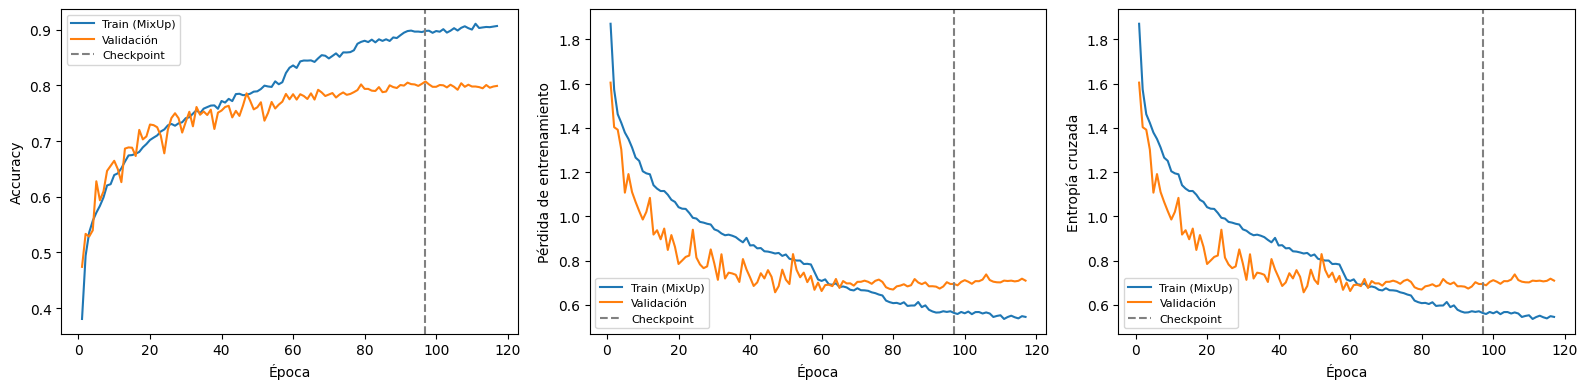

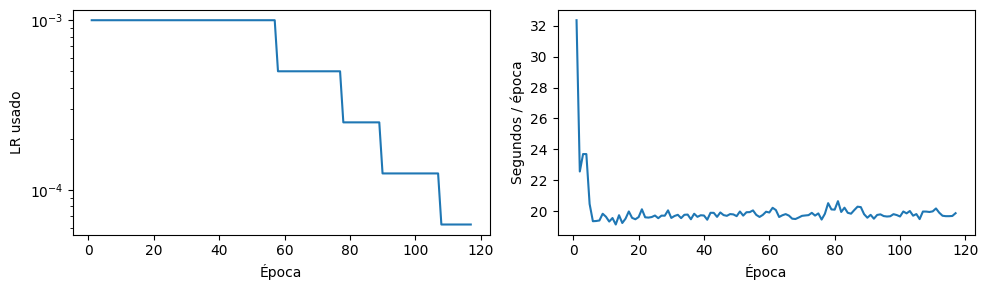

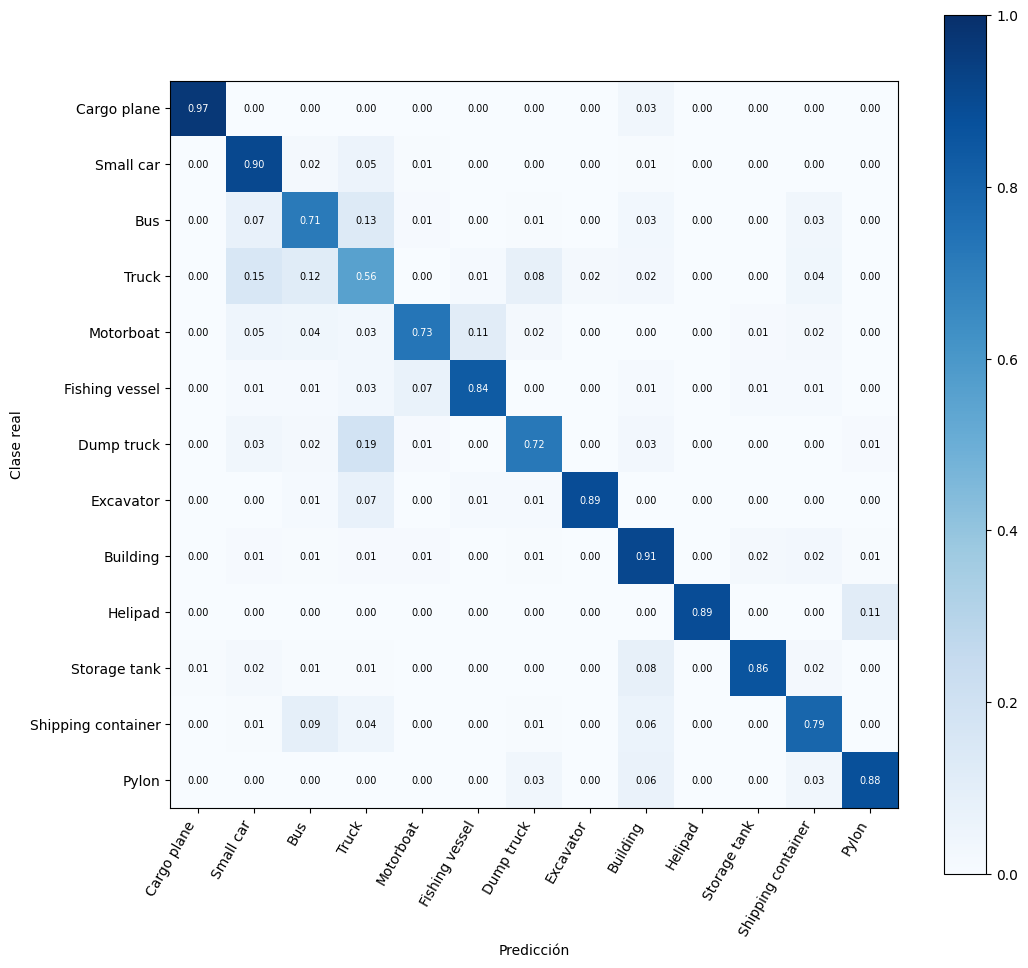

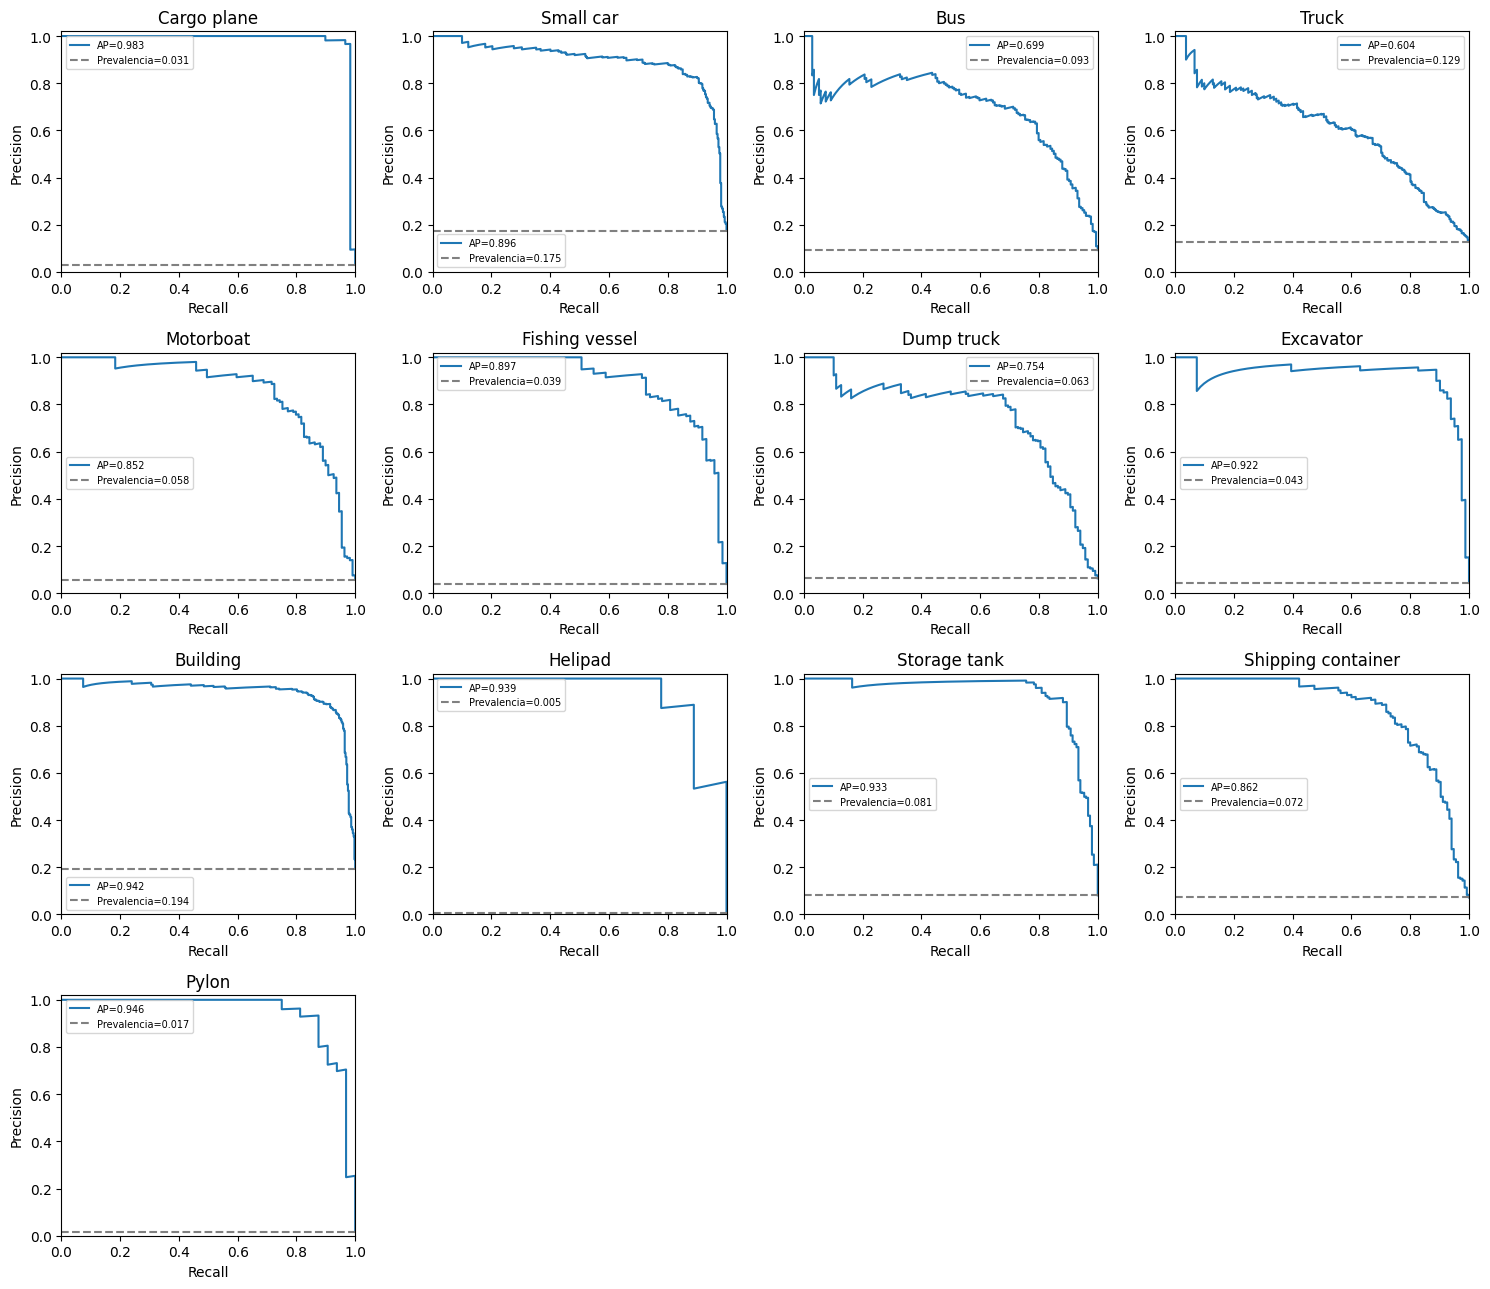

In [8]:
def plot_run(run_dir):
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    h = read_json(artifact_path(run_dir, 'history.json'))
    m = read_json(artifact_path(run_dir, 'metrics.json'))
    classes = cfg['class_names']
    plots = run_dir / 'plots'
    epochs = np.arange(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, title in zip(axes, ['accuracy', 'loss', 'ce'], ['Accuracy', 'Pérdida de entrenamiento', 'Entropía cruzada']):
        ax.plot(epochs, h[metric], label='Train (MixUp)' if cfg.get('mixup_alpha', 0) > 0 else 'Train (entrenamiento)')
        ax.plot(epochs, h['val_' + metric], label='Validación')
        ax.axvline(m['best_epoch'], color='grey', ls='--', label='Checkpoint')
        ax.set(xlabel='Época', ylabel=title)
        ax.legend(fontsize=8)
    save_figure(fig, plots, 'training_curves')
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].semilogy(epochs, h['lr_used'])
    axes[0].set(xlabel='Época', ylabel='LR usado')
    axes[1].plot(epochs, h['epoch_seconds'])
    axes[1].set(xlabel='Época', ylabel='Segundos / época')
    save_figure(fig, plots, 'learning_rate_time')
    with np.load(artifact_path(run_dir, 'validation_predictions.npz')) as saved:
        y, probs, cm = saved['y_true'], saved['probabilities'], saved['confusion_matrix']
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)
    ax.set(xticks=range(len(classes)), yticks=range(len(classes)), xticklabels=classes,
           yticklabels=classes, xlabel='Predicción', ylabel='Clase real')
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f'{norm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if norm[i, j] > 0.5 else 'black')
    save_figure(fig, plots, 'confusion_matrix')
    fig, axes = plt.subplots(4, 4, figsize=(15, 13))
    for i, (name, ax) in enumerate(zip(classes, axes.flat)):
        target = (y == i).astype(int)
        precision, recall, _ = precision_recall_curve(target, probs[:, i])
        ap = average_precision_score(target, probs[:, i])
        ax.plot(recall, precision, label=f'AP={ap:.3f}')
        ax.axhline(target.mean(), ls='--', color='grey', label=f'Prevalencia={target.mean():.3f}')
        ax.set(title=name, xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(fontsize=7)
    for ax in list(axes.flat)[len(classes):]:
        ax.set_visible(False)
    save_figure(fig, plots, 'precision_recall')

plot_run(RUN_DIR)

## 9. Comparar desde artefactos

Selecciona **custom experiment03 + custom experiment01 (mejor anterior por accuracy) + ResNet18 experiment04**.
El efecto de MixUp se evalúa frente a experiment01; la popular usa 192×192 y label smoothing 0.1,
por lo que esa referencia no aísla la arquitectura. Se exige mismo dataset, reparto y clases.

La tabla incluye `mixup_alpha` (0 para referencias sin mezcla). La figura compara accuracy, CE y LR
de validación; se omite la curva de accuracy de train de la ejecución con MixUp porque sus etiquetas
son blandas. Las curvas individuales sí la muestran, identificada como Train (MixUp).
La brecha final usa exclusivamente evaluaciones de imágenes originales.

Para regenerar tras reiniciar el kernel, ejecutar primera celda y esta sección con los artefactos
completos. Destino: `comparisons/custom_experiment03/`.


experiments/experiment03: acc=80.693%, F1=82.269%, CE=0.6946
popular_architectures/resnet18/experiment04: acc=80.107%, F1=82.238%, CE=0.7562
experiments/experiment01: acc=79.147%, F1=80.182%, CE=0.8089


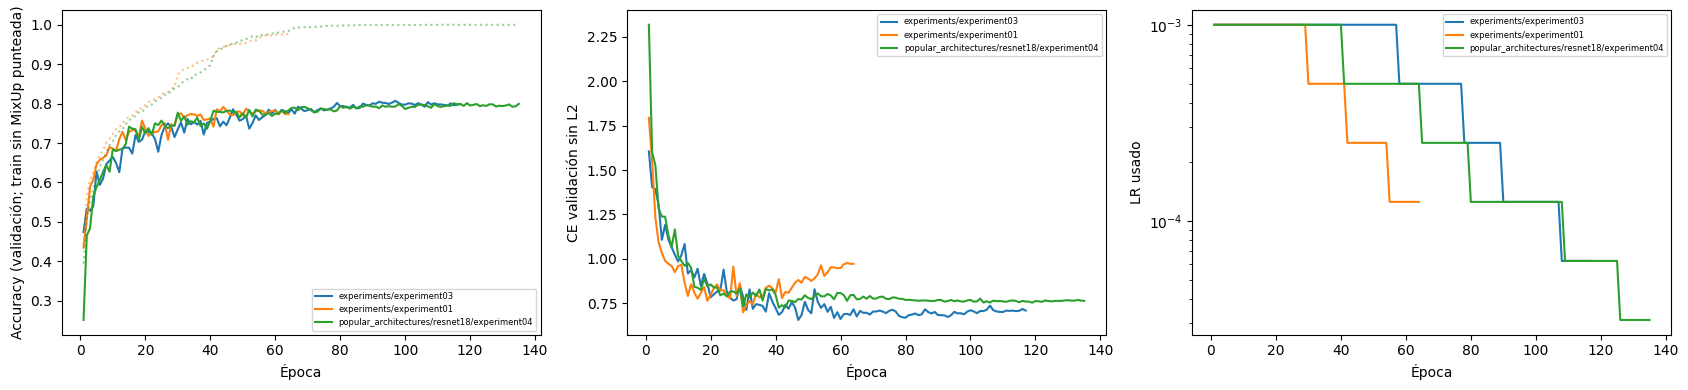

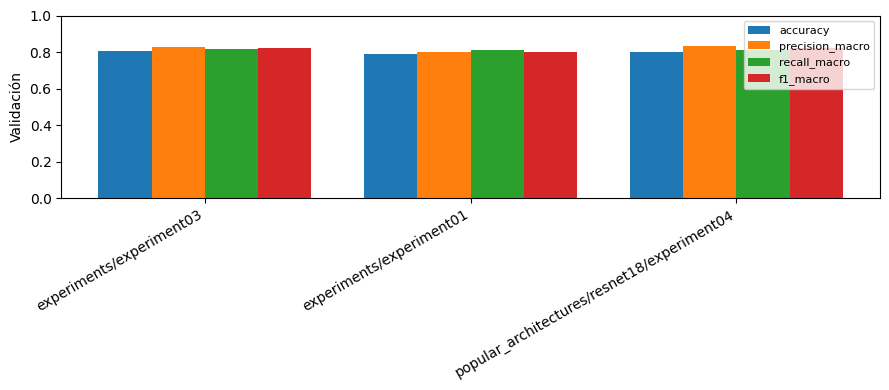

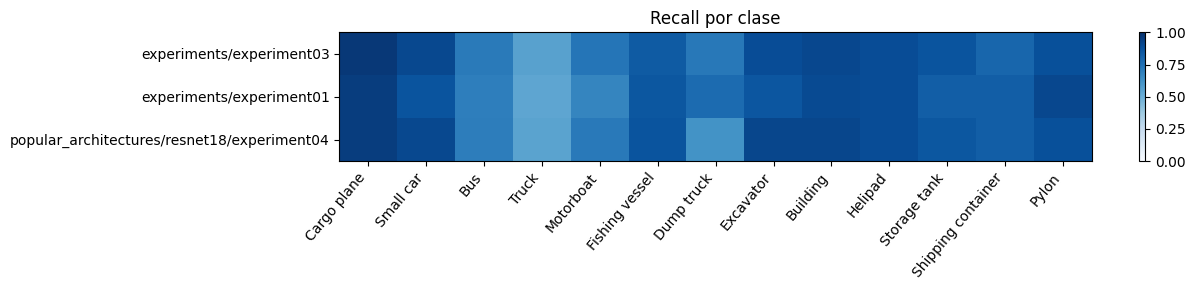

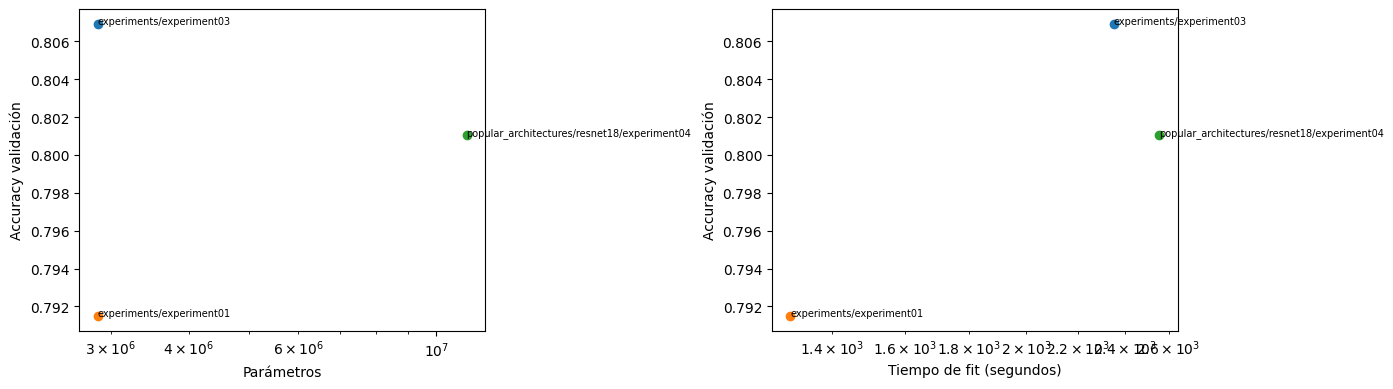

In [9]:
SELECT_RUNS = [
    'experiments/experiment03',
    'experiments/experiment01',
    'popular_architectures/resnet18/experiment04',
]

def load_runs(challenge_dir, selected=None):
    if selected:
        paths = [challenge_dir / p for p in selected]
    else:
        paths = set()
        for metrics_path in challenge_dir.rglob('metrics.json'):
            path = metrics_path.parent.parent if metrics_path.parent.name == 'artifacts' else metrics_path.parent
            if all(artifact_path(path, name).is_file() for name in ('config.json', 'history.json')):
                paths.add(path)
        paths = sorted(paths)
    runs = []
    for path in paths:
        for name in ('config.json', 'metrics.json', 'history.json'):
            if not artifact_path(path, name).is_file():
                raise FileNotFoundError(f'Ejecución incompleta: {path} ({name})')
        cfg = read_json(artifact_path(path, 'config.json'))
        m = read_json(artifact_path(path, 'metrics.json'))
        h = read_json(artifact_path(path, 'history.json'))
        if m.get('schema_version') != 1:
            raise ValueError(f'Esquema de métricas incompatible: {path}')
        signature = (cfg['split_hash'], cfg['data_hash'], cfg['class_names'])
        if runs and signature != runs[0]['signature']:
            raise ValueError(f'Dataset/reparto/clases incompatibles: {path}')
        if cfg['weights'] is not None or not cfg['all_layers_trainable']:
            raise ValueError(f'No es un entrenamiento desde cero: {path}')
        label = path.relative_to(challenge_dir).as_posix()
        runs.append({'path': path, 'config': cfg, 'metrics': m, 'history': h,
                     'label': label, 'signature': signature})
    return runs

def compare_runs(runs, directory):
    if not runs:
        print('Aún no hay experimentos completos para comparar.')
        return
    directory.mkdir(parents=True, exist_ok=True)
    rows = []
    for run in runs:
        c, m = run['config'], run['metrics']
        rows.append({'run': run['label'], 'architecture': c['architecture'], 'seed': c['seed'],
                     'resolution': 'x'.join(map(str, c['image_size'])), 'batch': c['batch_size'],
                     'optimizer': c['optimizer'], 'initial_lr': c['learning_rate'],
                     'dropout': c['dropout'], 'l2': c['l2'], 'augmentation': c['augmentation'],
                     'weight_decay': c.get('weight_decay', 0.0),
                     'label_smoothing': c.get('label_smoothing', 0.0),
                     'mixup_alpha': c.get('mixup_alpha', 0.0),
                     'augmentation_spec': json.dumps(c.get('augmentation_spec'), sort_keys=True),
                     'lr_factor': c['lr_factor'], 'lr_patience': c['lr_patience'],
                     'stop_patience': c['stop_patience'], 'min_lr': c['min_lr'],
                     'monitor': c['monitor'], 'max_epochs': c['max_epochs'],
                     'best_epoch': m['best_epoch'], 'epochs_run': m['epochs_run'],
                     'accuracy': m['accuracy'], 'precision_macro': m['precision_macro'],
                     'recall_macro': m['recall_macro'], 'f1_macro': m['f1_macro'], 'ap_macro': m['ap_macro'],
                     'ce': m['valid_inference']['ce'], 'gap_pp': m['accuracy_gap_pp'],
                     'params': m['params'], 'fit_seconds': m['fit_seconds'],
                     'predict_ms_per_image': m['predict_ms_per_image'],
                     'environment': json.dumps(c['environment'], sort_keys=True)})
    with (directory / 'comparison.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
    for row in sorted(rows, key=lambda r: r['accuracy'], reverse=True):
        print(f"{row['run']}: acc={row['accuracy']:.3%}, F1={row['f1_macro']:.3%}, CE={row['ce']:.4f}")
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for run in runs:
        h = run['history']
        epochs = np.arange(1, len(h['loss']) + 1)
        line, = axes[0].plot(epochs, h['val_accuracy'], label=run['label'])
        if run['config'].get('mixup_alpha', 0) == 0:
            axes[0].plot(epochs, h['accuracy'], ls=':', color=line.get_color(), alpha=0.5)
        axes[1].plot(epochs, h['val_ce'], label=run['label'])
        axes[2].plot(epochs, h['lr_used'], label=run['label'])
    for ax, title in zip(axes, ['Accuracy (validación; train sin MixUp punteada)', 'CE validación sin L2', 'LR usado']):
        ax.set(xlabel='Época', ylabel=title)
        ax.legend(fontsize=6)
    axes[2].set_yscale('log')
    save_figure(fig, directory, 'comparison_curves')
    names = [r['label'] for r in runs]
    x = np.arange(len(runs))
    fig, ax = plt.subplots(figsize=(max(9, len(runs) * 1.5), 4))
    for offset, key in enumerate(['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']):
        ax.bar(x + (offset - 1.5) * 0.2, [r['metrics'][key] for r in runs], width=0.2, label=key)
    ax.set(xticks=x, xticklabels=names, ylim=(0, 1), ylabel='Validación')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=8)
    save_figure(fig, directory, 'comparison_metrics')
    matrix = np.array([[c['recall'] for c in r['metrics']['class_metrics']] for r in runs])
    fig, ax = plt.subplots(figsize=(13, max(3, len(runs) * 0.6)))
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(len(runs[0]['config']['class_names'])), xticklabels=runs[0]['config']['class_names'],
           yticks=range(len(runs)), yticklabels=names, title='Recall por clase')
    plt.setp(ax.get_xticklabels(), rotation=50, ha='right')
    fig.colorbar(im, ax=ax)
    save_figure(fig, directory, 'comparison_class_recall')
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for run in runs:
        m = run['metrics']
        for ax, key in zip(axes, ['params', 'fit_seconds']):
            ax.scatter(m[key], m['accuracy'])
            ax.annotate(run['label'], (m[key], m['accuracy']), fontsize=7)
    for ax, title in zip(axes, ['Parámetros', 'Tiempo de fit (segundos)']):
        ax.set(xlabel=title, ylabel='Accuracy validación', xscale='log')
    save_figure(fig, directory, 'comparison_cost')
    # Agrupar solo configuraciones idénticas salvo semilla e identidad de ejecución.
    ignored = {'seed', 'experiment_id', 'hypothesis', 'initial_weights_sha256', 'environment',
               'data_load_seconds', 'cache_mode'}
    groups = {}
    for run in runs:
        key = digest_json({k: v for k, v in run['config'].items() if k not in ignored})
        groups.setdefault(key, []).append(run)
    summary = []
    for group in groups.values():
        seeds = [r['config']['seed'] for r in group]
        if len(seeds) != len(set(seeds)):
            raise ValueError('Semillas duplicadas para una misma configuración: revisa SELECT_RUNS.')
        entry = {'runs': [r['label'] for r in group], 'seeds': seeds, 'n': len(group)}
        for metric in ['accuracy', 'recall_macro', 'f1_macro']:
            values = [r['metrics'][metric] for r in group]
            entry[metric + '_mean'] = float(np.mean(values))
            entry[metric + '_std'] = float(np.std(values, ddof=1)) if len(group) > 1 else None
        summary.append(entry)
    write_json(directory / 'seed_summary.json', summary)

runs = load_runs(CHALLENGE_DIR, SELECT_RUNS)
compare_runs(runs, CHALLENGE_DIR / 'comparisons' / 'custom_experiment03')


## 10. Resultados · completar tras el entrenamiento

- **Hipótesis:** MixUp mejora validación y reduce errores de alta confianza.
- **Referencia:** custom experiment01; misma arquitectura e hiperparámetros, sin mezcla.
- **Factor probado:** MixUp alpha=0.2, lambda por imagen; label smoothing permanece 0.0.
- **Estado:** preparado; entrenamiento pendiente.
- **Mejor época / ejecutadas, accuracy y F1 macro:** consultar `artifacts/metrics.json`.
- **Cambios frente a experiment01 en accuracy, F1, CE sin suavizado y AP:** [completar].
- **Brecha y train:** usar `train_inference` sin mezcla; no comparar accuracy de fit con train anterior.
- **Confianza de errores, vehículos y soporte de Helipad:** [completar].
- **Coste y comparación con ResNet18 experiment04:** [completar].
- **Conclusión:** [¿se convierte en mejor custom por accuracy?; límites de una semilla/partición].
- **Codabench, si se envió:** [fecha y resultado separado de validación].
